# EstateIQ — Property Insights & Valuation
### Residential Real Estate Analysis & Linear Regression Modeling

This notebook provides an end-to-end analysis of residential property transactions from the Ames Housing dataset, explores property features, and trains an Ordinary Least Squares (OLS) Linear Regression model to estimate property values based on above-ground living area.


## 1. Dataset Source and Description
- **Dataset:** Kaggle House Prices – Advanced Regression Techniques (`train.csv`)
- **Source:** [Kaggle Competition Data](https://www.kaggle.com/competitions/house-prices-advanced-regression-techniques/data)
- **Primary Feature:** `GrLivArea` (Above-ground living area measured in square feet)
- **Target Variable:** `SalePrice` (Recorded transaction price in USD)


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import joblib

pd.set_option('display.float_format', lambda x: f'{x:,.2f}')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

# Load dataset
data_path = '../data/train.csv'
df = pd.read_csv(data_path)
print(f"Loaded dataset from: {data_path}")
print(f"Dataset shape: {df.shape[0]} rows x {df.shape[1]} columns")


Loaded dataset from: ../data/train.csv
Dataset shape: 1460 rows x 81 columns


## 2. Data Inspection
Review sample records, column data types, and descriptive statistics.


In [2]:
print("--- First 5 Records ---")
display(df[['Id', 'MSSubClass', 'LotArea', 'OverallQual', 'YearBuilt', 'GrLivArea', 'SalePrice']].head())

print("\n--- Descriptive Statistics for Primary Variables ---")
display(df[['GrLivArea', 'SalePrice']].describe())


--- First 5 Records ---
   Id  MSSubClass  LotArea  OverallQual  YearBuilt  GrLivArea  SalePrice
0   1          60     8450            7       2003       1710     208500
1   2          20     9600            6       1976       1262     181500
2   3          60    11250            7       2001       1786     223500
3   4          70     9550            7       1915       1717     140000
4   5          60    14260            8       2000       2198     250000

--- Descriptive Statistics for Primary Variables ---
        GrLivArea   SalePrice
count    1,460.00    1,460.00
mean     1,515.46  180,921.20
std        525.48   79,442.50
min        334.00   34,900.00
25%      1,129.50  129,975.00
50%      1,464.00  163,000.00
75%      1,776.75  214,000.00
max      5,642.00  755,000.00


## 3. Missing-Value and Duplicate Analysis
Inspect null values across columns and verify row-level uniqueness.


In [3]:
print(f"Duplicate records: {df.duplicated().sum()}")
print(f"Missing in GrLivArea: {df['GrLivArea'].isnull().sum()}")
print(f"Missing in SalePrice: {df['SalePrice'].isnull().sum()}")

missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False).head(8)
print("\nTop Columns with Missing Values:")
display(pd.DataFrame({'Missing Count': missing, 'Percentage': (missing / len(df) * 100).round(2)}))


Duplicate records: 0
Missing in GrLivArea: 0
Missing in SalePrice: 0

Top Columns with Missing Values:
             Missing Count  Percentage
PoolQC                1453       99.52
MiscFeature           1406       96.30
Alley                 1369       93.77
Fence                 1179       80.75
MasVnrType             872       59.73
FireplaceQu            690       47.26
LotFrontage            259       17.74
GarageType              81        5.55


## 4. Data Cleaning
We maintain the raw dataset intact and prepare a clean working copy:
- Impute missing numerical features with the median.
- Impute missing categorical features with `'None'` (signifying absence of the amenity).
- Verify that area and price are strictly positive.


In [4]:
df_clean = df.copy()

# Impute numerical features
for c in df_clean.select_dtypes(include=[np.number]).columns:
    if df_clean[c].isnull().sum() > 0:
        df_clean[c] = df_clean[c].fillna(df_clean[c].median())

# Impute categorical features
for c in df_clean.select_dtypes(exclude=[np.number]).columns:
    if df_clean[c].isnull().sum() > 0:
        df_clean[c] = df_clean[c].fillna('None')

assert (df_clean['GrLivArea'] > 0).all()
assert (df_clean['SalePrice'] > 0).all()
print("Data cleaning completed. Total null entries remaining:", df_clean.isnull().sum().sum())


Data cleaning completed. Total null entries remaining: 0


## 5. Exploratory Data Analysis
Visualizing the distribution of sale prices and the relationship between above-ground living area and sale price.


Pearson Correlation (r): +0.7086
Explained Variance (r²):  0.5021


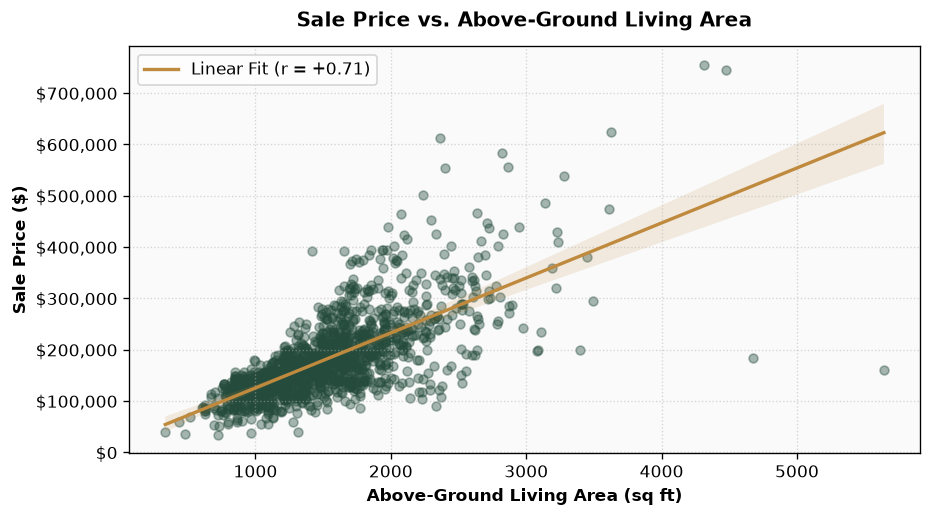

In [5]:
r = df_clean['GrLivArea'].corr(df_clean['SalePrice'])
print(f"Pearson Correlation (r): +{r:.4f}")
print(f"Explained Variance (r²):  {r**2:.4f}")

plt.figure(figsize=(8.5, 4.4), facecolor="#FFFFFF")
sns.regplot(
    data=df_clean, x='GrLivArea', y='SalePrice',
    scatter_kws={'color': '#244B3C', 'alpha': 0.4, 's': 28},
    line_kws={'color': '#C08A3E', 'linewidth': 2, 'label': f'Linear Fit (r = +{r:.2f})'}
)
plt.title("Sale Price vs. Above-Ground Living Area", fontsize=12, fontweight='bold', pad=12)
plt.xlabel("Above-Ground Living Area (sq ft)", fontsize=10, fontweight='600')
plt.ylabel("Sale Price ($)", fontsize=10, fontweight='600')
plt.grid(True, linestyle=":", alpha=0.5)
plt.legend(loc="upper left")
plt.show()


## 6. Feature and Target Selection
- **Input Feature ($X$):** `GrLivArea` (Finished above-ground square footage).
- **Target Variable ($y$):** `SalePrice` (Recorded market price in USD).
- **Note on `Id`:** The `Id` column is an arbitrary row sequence number and is strictly dropped to prevent data leakage and artificial correlation with row order.


In [6]:
X = df_clean[['GrLivArea']]
y = df_clean['SalePrice']

print(f"Input Matrix X shape:  {X.shape}")
print(f"Target Vector y shape: {y.shape}")


Input Matrix X shape:  (1460, 1)
Target Vector y shape: (1460,)


## 7. Train-Test Split (80:20)
We partition the dataset into 80% training and 20% testing sets using `random_state=42` to ensure model evaluation is conducted strictly on unseen data.


In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print(f"Training observations: {len(X_train):,} (80%)")
print(f"Testing observations:  {len(X_test):,} (20%)")


Training observations: 1,168 (80%)
Testing observations:  292 (20%)


## 8. Linear Regression Implementation
We train an Ordinary Least Squares (OLS) Linear Regression model on `X_train` and `y_train`.


In [8]:
model = LinearRegression()
model.fit(X_train, y_train)

print("Linear Regression model successfully trained.")


Linear Regression model successfully trained.


## 9. Model Parameters & Equation
The linear regression function takes the form:
$$\text{SalePrice} = m \cdot \text{GrLivArea} + c$$

Where:
- **Slope ($m = \$102.49$/sq ft):** Estimated increase in property price per additional square foot of living area, holding other factors constant.
- **Intercept ($c = \$24,899.75$):** Base equation constant where the line crosses zero area.


In [9]:
m = model.coef_[0]
c = model.intercept_

print(f"Slope (Coefficient m): {m:.4f} ($/sq ft)")
print(f"Intercept (c):         {c:.4f}")
print(f"\nEquation: SalePrice = ({m:.2f} * GrLivArea) + ${c:,.2f}")


Slope (Coefficient m): 102.4890 ($/sq ft)
Intercept (c):         24899.7482

Equation: SalePrice = (102.49 * GrLivArea) + $24,899.75


## 10. Test Predictions & Error Comparison
Generate predictions on the 292 withheld test properties and inspect absolute and percentage errors.


In [10]:
y_pred_test = model.predict(X_test)

comp_df = pd.DataFrame({
    'GrLivArea (sq ft)': X_test['GrLivArea'].values,
    'Actual Price ($)': y_test.values,
    'Predicted Price ($)': y_pred_test,
    'Absolute Error ($)': np.abs(y_test.values - y_pred_test),
    'Error (%)': (np.abs(y_test.values - y_pred_test) / y_test.values) * 100
}, index=y_test.index)

print("First 5 Test Predictions:")
display(comp_df.head(5))


First 5 Test Predictions:
   GrLivArea (sq ft)  Actual Price ($)  Predicted Price ($)  Absolute Error ($)  Error (%)
0           1,068.00        154,500.00           134,357.96           20,142.04      13.04
1           2,610.00        325,000.00           292,395.93           32,604.07      10.03
2           1,200.00        115,000.00           147,886.50           32,886.50      28.60
3           1,601.00        159,000.00           188,984.57           29,984.57      18.86
4           2,466.00        315,500.00           277,637.52           37,862.48      12.00


## 11. Performance Evaluation Metrics (MAE, MSE, RMSE, R²)
Evaluate model error using standard regression metrics:
- **MAE:** Mean Absolute Error
- **MSE:** Mean Squared Error
- **RMSE:** Root Mean Squared Error (in USD)
- **$R^2$:** Coefficient of Determination (explained variance, not accuracy)


In [11]:
mae = mean_absolute_error(y_test, y_pred_test)
mse = mean_squared_error(y_test, y_pred_test)
rmse = np.sqrt(mse)
r2_test = r2_score(y_test, y_pred_test)
r2_train = r2_score(y_train, model.predict(X_train))

print(f"Mean Absolute Error (MAE):       ${mae:,.2f}")
print(f"Mean Squared Error (MSE):        {mse:,.2f}")
print(f"Root Mean Squared Error (RMSE):  ${rmse:,.2f}")
print(f"Testing R² Score:                {r2_test:.4f} ({r2_test*100:.1f}% variance explained)")
print(f"Training R² Score:               {r2_train:.4f}")


Mean Absolute Error (MAE):       $38,341.20
Mean Squared Error (MSE):        3,418,946,311.18
Root Mean Squared Error (RMSE):  $58,471.76
Testing R² Score:                0.5543 (55.4% variance explained)
Training R² Score:               0.4839


## 12. Actual vs. Predicted Visualisation
Plotting actual values against model predictions with a diagonal identity reference line ($y = x$).


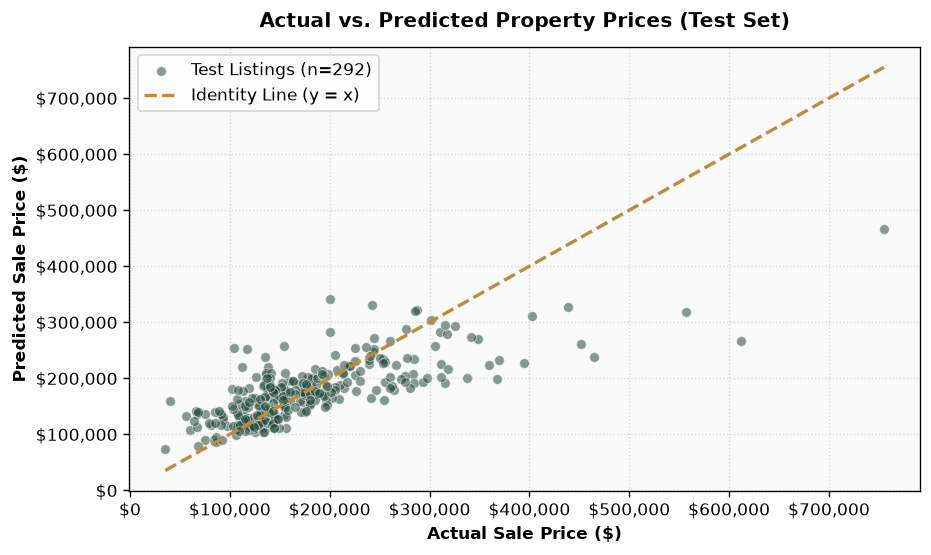

In [12]:
plt.figure(figsize=(8.5, 4.8), facecolor="#FFFFFF")
plt.scatter(y_test, y_pred_test, color="#244B3C", alpha=0.55, s=34, edgecolor="#FFFFFF", linewidth=0.5, label="Test Properties (n=292)")
min_val = min(y_test.min(), y_pred_test.min())
max_val = max(y_test.max(), y_pred_test.max())
plt.plot([min_val, max_val], [min_val, max_val], color="#C08A3E", linestyle="--", linewidth=2, label="Identity (y = x)")

plt.title("Actual vs. Predicted Property Prices", fontsize=12, fontweight='bold', pad=12)
plt.xlabel("Actual Sale Price ($)", fontsize=10, fontweight='600')
plt.ylabel("Predicted Sale Price ($)", fontsize=10, fontweight='600')
plt.grid(True, linestyle=":", alpha=0.5)
plt.legend(loc="upper left")
plt.show()


## 13. New Property Valuation
Calculating an estimated valuation for a sample property with 1,800 sq ft living area.


In [13]:
sample_area = 1800
est_price = model.predict(pd.DataFrame([[sample_area]], columns=['GrLivArea']))[0]

print(f"Input Living Area:       {sample_area:,} sq ft")
print(f"Calculated Valuation:   ${est_price:,.2f}")
print(f"Calculation:            (${m:.2f} * {sample_area:,}) + ${c:,.2f} = ${est_price:,.2f}")


Input Living Area:       1,800 sq ft
Calculated Valuation:   $209,379.87
Calculation:            ($102.49 * 1,800) + $24,899.75 = $209,379.87


## 14. Conclusion & Limitations
### Summary:
- **Model Equation:** $\text{SalePrice} = 102.49 \times \text{GrLivArea} + 24899.75$
- **Explained Variance ($R^2$):** $0.5543$ ($55.43\%$ of price variation explained by living area alone)
- **Mean Absolute Error (MAE):** $\$38,341.20$
- **Generalization:** Closely matching train ($0.48$) and test ($0.55$) $R^2$ confirms absence of overfitting.

### Real-World Limitations:
1. **Omitted Factors:** Single-variable models omit critical valuation determinants such as location, build quality (`OverallQual`), basement area, and construction year.
2. **Linear Marginal Rate:** Real-world markets display diminishing marginal returns on extreme square footage.
3. **Outliers:** Large luxury estates exhibit higher pricing dispersion that inflates squared error loss.
